# Spotted star from Kochukhov (2017), Sect. 3.1 of the SPICE paper (R3 version)

Replaces `kochukhov2017.ipynb` / `kochukhov2017_los_fixed.ipynb`. Changes relative to the R2 figures, all prompted by the referee:

* **Abundances.** Kochukhov (2017) specifies $\log(N_{\rm Fe}/N_{\rm tot}) = -4.0$ in the photosphere and $-2.5$ in the spot centres. Converted to the Magg et al. (2022) scale used by the Turbospectrum grid ($A({\rm Fe})_\odot = 7.46$, $\log N_{\rm H}/N_{\rm tot} = -0.035$) these are $A({\rm Fe}) = 8.035$ and $9.535$, i.e. [Fe/H] $= +0.57$ and $+2.07$ — not [Fe/H] $= -4.0$ / $-2.5$ as in the earlier notebooks.
* **Spectral grid.** `data/kochukhov2017_fe_lte.zarr`: Turbospectrum LTE intensities for the MARCS $T_{\rm eff}=8000$ K, $\log g=4.0$, [M/H] $=0$ model, $\xi = 2$ km/s, with the Fe abundance set in the line synthesis as an individual abundance on 17 nodes $A({\rm Fe}) = 8.0 \ldots 9.6$ (0.1 dex), 20 $\mu$ angles, 5000–5020 Å at 0.01 Å. Generated with our Turbospectrum fork (https://github.com/maja-jablonska/Turbospectrum_NLTE) from `config_kochukhov2017_fe_lte.json` in this directory. LTE because Kochukhov (2017) used LTE line formation, and because the NLTE departure grids are tabulated for scaled-solar Fe, not for a 2 dex Fe excess.
* **Lines.** Fe I 5005.71 and 5006.12 Å, two of the seven lines used by Kochukhov (2017), blended at $v\sin i = 40$ km/s. Profiles are convolved to $R = 110\,000$ as in that paper.
* **Geometry.** Rotation axis passed explicitly as $z$ (the axis the spot latitudes/longitudes and `inclination_to_los_axis` are defined about); solar radius, so $P_{\rm rot} = 26.3$ h for $v\sin i = 40$ km/s and $i = 60^\circ$; 20 equidistant phases. Spots: inner radius 15°, outer radius 30°, abundance interpolated linearly in between (Kochukhov 2017), at latitudes $-30, 0, +30, +60^\circ$, equidistant in longitude; the longitudes and phase zero point were fitted to the input map of Kochukhov (2017), Fig. 3a, so panel (c) of the mesh figure can be compared with it directly.
* **Figures.** Real flux axes, phase labelled as "phase", latitude labelled as "lat".


In [2]:
import sys, time, pickle
from pathlib import Path
REPO = Path.cwd().resolve().parents[2]  # this notebook lives in tutorial/paper_results/spots
sys.path.insert(0, str(REPO / 'src'))

import numpy as np
import jax
import jax.numpy as jnp
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from mpl_toolkits.mplot3d import art3d
from tqdm.auto import tqdm

from spice.spectrum.lazy_zarr_interpolator import IntensityLazyZarrInterpolator
from spice.models import IcosphereModel
from spice.models.mesh_transform import add_rotation, evaluate_rotation
from spice.models.mesh_view import get_mesh_view
from spice.models.utils import inclination_to_los_axis, lat_to_theta, lon_to_phi, velocity_to_period
from spice.spectrum import simulate_observed_flux
from spice.plots.plot_mesh import _mesh_center, _set_axes_centered, _single_mesh_arrow_vectors

%matplotlib inline
plt.rcParams.update({'font.size': 11, 'axes.labelsize': 12, 'legend.fontsize': 10})


## Spectral grid and the Fe abundances of Kochukhov (2017)

In [3]:
GRID_PATH = str(REPO / 'data' / 'kochukhov2017_fe_lte.zarr')
line_interp = IntensityLazyZarrInterpolator(GRID_PATH, params=['teff', 'logg', 'fe', 'mu', 'vmicro'], sparse=True)
print('grid axes:', line_interp.stellar_parameter_names)
print('min:', line_interp.min_stellar_parameters, ' max:', line_interp.max_stellar_parameters)

# Kochukhov (2017) gives Fe as log(N_Fe/N_tot). Turbospectrum takes A(Fe) = 12 + log(N_Fe/N_H).
# On the Magg et al. (2022) scale A(He) = 10.914, so N_H/N_tot = 1/(1 + 0.082 + 0.001) and
# log(N_H/N_tot) = -0.035.
A_FE_SUN = 7.46          # Magg et al. (2022)
LOG_NH_NTOT = -0.035

def log_nfe_ntot_to_afe(log_nfe_ntot):
    return log_nfe_ntot + 12.0 - LOG_NH_NTOT

A_FE_BG = log_nfe_ntot_to_afe(-4.0)     # photosphere
A_FE_SPOT = log_nfe_ntot_to_afe(-2.5)   # spot centres
print(f'photosphere A(Fe) = {A_FE_BG:.3f}  ([Fe/H] = {A_FE_BG - A_FE_SUN:+.2f})')
print(f'spot centre A(Fe) = {A_FE_SPOT:.3f}  ([Fe/H] = {A_FE_SPOT - A_FE_SUN:+.2f})')


[spice] zarr loaded in 1.0 s
[spice] Building sparse grid index...
[spice] Sparse grid index ready.


[spice] Loading data:   0%|          | 0/3 [00:00<?, ?it/s]

[spice] Spectral grid loaded in 2.4 s
grid axes: ['teff', 'logg', 'fe', 'vmicro']
min: [8.e+03 4.e+00 8.e+00 2.e+00]  max: [8.0e+03 4.0e+00 9.6e+00 2.0e+00]
photosphere A(Fe) = 8.035  ([Fe/H] = +0.58)
spot centre A(Fe) = 9.535  ([Fe/H] = +2.08)


## Star, rotation and viewing geometry

In [4]:
TEFF, LOGG, VMICRO = 8000., 4.0, 2.0
RADIUS, MASS = 1.0, 1.5          # solar radii, solar masses (mass only sets log g if override_log_g)
INCL = 60.                       # degrees
VSINI = 40.                      # km/s
V_EQ = VSINI / np.sin(np.deg2rad(INCL))

m = IcosphereModel.construct(
    10000, RADIUS, MASS,
    line_interp.to_parameters({'teff': TEFF, 'logg': LOGG, 'fe': A_FE_BG, 'vmicro': VMICRO}),
    line_interp.stellar_parameter_names, override_log_g=False)

# The spot latitudes/longitudes (lat_to_theta, lon_to_phi) and inclination_to_los_axis are all
# defined about the z axis, so the rotation axis must be z. Leaving it to the default (which is
# derived from the construction-time line of sight and is NOT z) silently changed the inclination
# to 30 degrees in the R2 figures.
ROTATION_AXIS = jnp.array([0., 0., 1.])
mt = get_mesh_view(add_rotation(m, V_EQ, rotation_axis=ROTATION_AXIS),
                   los_vector=inclination_to_los_axis(INCL))

PERIOD_S = float(velocity_to_period(V_EQ, RADIUS))
PERIOD_H = PERIOD_S / 3600.
print(f'{mt.mesh_elements.shape[0]} surface elements')
print(f'v_eq = {V_EQ:.2f} km/s, P_rot = {PERIOD_H:.2f} h')


[spice] IcosphereModel constructed in 1.8 s
20480 surface elements
v_eq = 46.19 km/s, P_rot = 26.29 h


## Spots: Kochukhov (2017) geometry, abundance ramp between 15° and 30°

In [5]:
FE_IDX = line_interp.stellar_parameter_names.index('fe')
SPOT_LATS = [-30., 0., 30., 60.]
# Equidistant in longitude. The zero point and the order were fitted to the input map of
# Kochukhov (2017), Fig. 3a (spot centroids digitised at phases 0.0-0.8): at phase 0 the spots at
# lat -30, 0, +30, +60 sit 40, 130, 310 and 220 deg from the central meridian and move from left to
# right. With the observer at (0, -sin i, cos i) the central meridian is at lon = -90 deg.
SPOT_LONS = [-50., 40., 220., 130.]
R_IN, R_OUT = 15., 30.                   # degrees
SPOT_COLORS = ["#1B9E77", "#D95F02", "#7570B3", "#E7298A"]
SPOT_LABELS = [f'lat = {int(l):+d}°'.replace('+0°', '0°') for l in SPOT_LATS]


def spot_weight(mesh, lat_deg, lon_deg):
    # 1 inside R_IN, 0 outside R_OUT, linear in angular distance in between.
    c = np.asarray(mesh.d_centers, dtype=float)
    c = c / np.linalg.norm(c, axis=1, keepdims=True)
    th, ph = float(lat_to_theta(lat_deg)), float(lon_to_phi(lon_deg))
    s = np.array([np.sin(th) * np.cos(ph), np.sin(th) * np.sin(ph), np.cos(th)])
    d = np.degrees(np.arccos(np.clip(c @ s, -1.0, 1.0)))
    return np.clip((R_OUT - d) / (R_OUT - R_IN), 0.0, 1.0)


def with_fe(mesh, weight):
    params = np.array(mesh.parameters)
    params[:, FE_IDX] = A_FE_BG + weight * (A_FE_SPOT - A_FE_BG)
    return mesh._replace(parameters=jnp.asarray(params, dtype=mesh.parameters.dtype))


W_SPOTS = np.stack([spot_weight(mt, la, lo) for la, lo in zip(SPOT_LATS, SPOT_LONS)], axis=1)  # (faces, 4)
ms_all = with_fe(mt, W_SPOTS.max(axis=1))
ms_single = [with_fe(mt, W_SPOTS[:, k]) for k in range(len(SPOT_LATS))]
print('faces inside the inner radius of each spot:', (W_SPOTS >= 0.999).sum(axis=0))
print('faces with any enhancement:', (W_SPOTS.max(axis=1) > 0).sum())


faces inside the inner radius of each spot: [325 352 325 355]
faces with any enhancement: 5486


## Geometry self-check (the R2 figures failed every line of this)

In [6]:
axis = np.asarray(mt.rotation_axis, float); axis /= np.linalg.norm(axis)
los = np.asarray(mt.los_vector, float); los /= np.linalg.norm(los)
angle_axis_los = np.degrees(np.arccos(abs(axis @ los)))
print(f'rotation axis = {axis}, LOS = {los}')
print(f'angle between rotation axis and LOS = {angle_axis_los:.2f} deg (expected {INCL:.0f})')
assert abs(angle_axis_los - INCL) < 0.01

m0 = evaluate_rotation(mt, 0.0)
vis = np.asarray(m0.mus) > 0
vmax = np.abs(np.asarray(m0.los_velocities)[vis]).max()
print(f'max |v_los| on the visible disc = {vmax:.2f} km/s (expected ~{VSINI:.0f})')
assert abs(vmax - VSINI) < 1.0

# Extreme mu reached by each spot centre over a rotation, for i = 60 deg:
# mu = sin(lat) cos(i) +/- cos(lat) sin(i).
i_rad = np.deg2rad(INCL)
for lat in SPOT_LATS:
    b = np.deg2rad(lat)
    mu_max = np.sin(b) * np.cos(i_rad) + np.cos(b) * np.sin(i_rad)
    mu_min = np.sin(b) * np.cos(i_rad) - np.cos(b) * np.sin(i_rad)
    print(f'spot at lat {lat:+5.1f}: spot-centre mu ranges from {mu_min:+.2f} to {mu_max:+.2f}')


rotation axis = [0. 0. 1.], LOS = [ 0.          0.86602543 -0.49999996]
angle between rotation axis and LOS = 60.00 deg (expected 60)
max |v_los| on the visible disc = 39.98 km/s (expected ~40)
spot at lat -30.0: spot-centre mu ranges from -1.00 to +0.50
spot at lat  +0.0: spot-centre mu ranges from -0.87 to +0.87
spot at lat +30.0: spot-centre mu ranges from -0.50 to +1.00
spot at lat +60.0: spot-centre mu ranges from +0.00 to +0.87


## Rotation phases

In [7]:
N_PHASES = 20   # as in Kochukhov (2017)
timestamps = np.linspace(0.0, PERIOD_S, N_PHASES, endpoint=False)
phases = timestamps / PERIOD_S

mts_all = [evaluate_rotation(ms_all, float(t)) for t in tqdm(timestamps, desc='all spots')]
mts_single = [[evaluate_rotation(ms, float(t)) for t in timestamps] for ms in tqdm(ms_single, desc='single spots')]
m_nospot = evaluate_rotation(mt, 0.0)   # axisymmetric: phase independent

# Visible projected-area fraction of each spot (w > 0.5) over the cycle.
for k, (lat, seq) in enumerate(zip(SPOT_LATS, mts_single)):
    spot = W_SPOTS[:, k] > 0.5
    fr = []
    for mm in seq:
        a = np.asarray(mm.visible_cast_areas)
        fr.append(a[spot].sum() / a.sum())
    fr = np.array(fr)
    print(f'spot lat {lat:+5.1f}: visible area fraction min {fr.min():.4f} max {fr.max():.4f}, '
          f'hidden at {int((fr < 1e-4).sum())}/{N_PHASES} phases')
    assert fr.max() > 0.01, f'spot at latitude {lat} is never visible'


all spots:   0%|          | 0/20 [00:00<?, ?it/s]

single spots:   0%|          | 0/4 [00:00<?, ?it/s]

spot lat -30.0: visible area fraction min 0.0000 max 0.0734, hidden at 9/20 phases
spot lat  +0.0: visible area fraction min 0.0000 max 0.1265, hidden at 7/20 phases
spot lat +30.0: visible area fraction min 0.0000 max 0.1458, hidden at 4/20 phases
spot lat +60.0: visible area fraction min 0.0126 max 0.1268, hidden at 0/20 phases


## Spectral synthesis

In [8]:
WL_MIN, WL_MAX, WL_STEP = 5002.5, 5009.5, 0.01
vws = np.arange(WL_MIN, WL_MAX + WL_STEP / 2, WL_STEP)
log_vws = jnp.log10(jnp.asarray(vws))


def synth(mesh):
    return np.asarray(simulate_observed_flux(line_interp.intensity, mesh, log_vws))


t0 = time.time()
spec_nospot = synth(m_nospot)
print(f'one synthesis ({len(vws)} wavelengths, {m_nospot.mesh_elements.shape[0]} elements): {time.time() - t0:.1f} s')
spec_all = [synth(mm) for mm in tqdm(mts_all, desc='all spots')]
spec_single = [[synth(mm) for mm in tqdm(seq, desc=f'spot lat {lat:+.0f}')]
               for lat, seq in zip(SPOT_LATS, mts_single)]


/Users/mjablons/anaconda3/envs/astro/lib/python3.11/site-packages/jax/_src/numpy/array_methods.py:125: UserWarning: Explicitly requested dtype int64 requested in astype is not available, and will be truncated to dtype int32. To enable more dtypes, set the jax_enable_x64 configuration option or the JAX_ENABLE_X64 shell environment variable. See https://github.com/jax-ml/jax#current-gotchas for more.
  return lax_numpy.astype(self, dtype, copy=copy, device=device)


one synthesis (701 wavelengths, 20480 elements): 3.8 s


all spots:   0%|          | 0/20 [00:00<?, ?it/s]

spot lat -30:   0%|          | 0/20 [00:00<?, ?it/s]

spot lat +0:   0%|          | 0/20 [00:00<?, ?it/s]

spot lat +30:   0%|          | 0/20 [00:00<?, ?it/s]

spot lat +60:   0%|          | 0/20 [00:00<?, ?it/s]

In [9]:
R_INST = 110000.   # Kochukhov (2017) convolved the simulated spectra to R = 110,000


def normalise(spec):
    return spec[:, 0] / spec[:, 1]


def convolve_to_R(norm_flux, wl, R):
    sigma_px = (wl.mean() / R / 2.3548) / WL_STEP
    half = int(np.ceil(5 * sigma_px))
    x = np.arange(-half, half + 1)
    kernel = np.exp(-0.5 * (x / sigma_px) ** 2)
    kernel /= kernel.sum()
    padded = np.pad(norm_flux, half, mode='edge')
    return np.convolve(padded, kernel, mode='valid')


nospot_norm = convolve_to_R(normalise(spec_nospot), vws, R_INST)
all_norm = [convolve_to_R(normalise(s), vws, R_INST) for s in spec_all]
single_norm = [[convolve_to_R(normalise(s), vws, R_INST) for s in seq] for seq in spec_single]

with open('kochukhov2017_fe_lte_spectra.pkl', 'wb') as f:
    pickle.dump({
        'wavelengths': vws, 'phases': phases, 'period_s': PERIOD_S,
        'spec_nospot': spec_nospot, 'spec_all': spec_all, 'spec_single': spec_single,
        'spot_lats': SPOT_LATS, 'spot_lons': SPOT_LONS, 'r_in': R_IN, 'r_out': R_OUT,
        'a_fe_bg': A_FE_BG, 'a_fe_spot': A_FE_SPOT, 'teff': TEFF, 'logg': LOGG, 'vmicro': VMICRO,
        'incl': INCL, 'vsini': VSINI, 'radius': RADIUS, 'grid': GRID_PATH, 'R_inst': R_INST,
    }, f)

depth_raw = 1 - normalise(spec_nospot).min()
depth_conv = 1 - nospot_norm.min()
sig = np.array([np.abs(a - nospot_norm).max() for a in all_norm])
print(f'photospheric blend depth: {depth_raw:.3f} of the continuum unconvolved, {depth_conv:.3f} at R = {R_INST:.0f}')
print(f'spot signature |spotted - unspotted|: max {100 * sig.max():.1f}% of the continuum (min over phases {100 * sig.min():.1f}%)')


photospheric blend depth: 0.220 of the continuum unconvolved, 0.220 at R = 110000
spot signature |spotted - unspotted|: max 7.6% of the continuum (min over phases 2.4%)


## Figure: mesh model (paper Fig. 7)

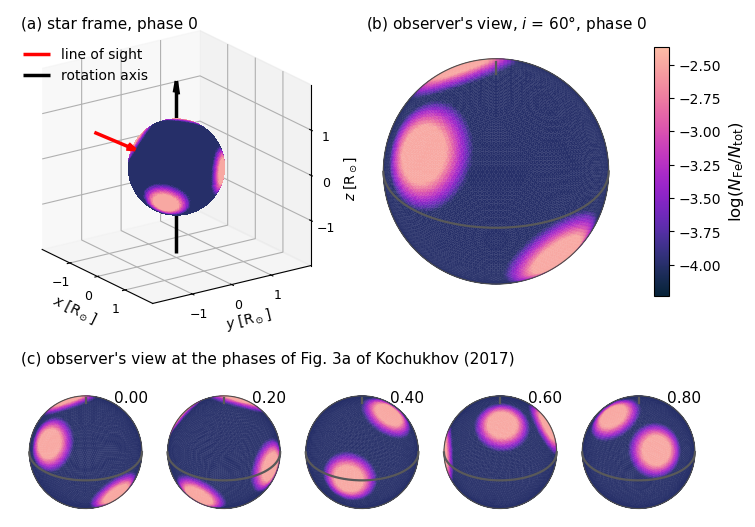

In [10]:
# Colour scale in log(N_Fe/N_tot), the quantity Kochukhov (2017) quotes; dark = iron-rich as in his Fig. 3.
import cmasher as cmr

def afe_to_log_nfe_ntot(afe):
    return afe - 12.0 + LOG_NH_NTOT


fe_all = afe_to_log_nfe_ntot(np.asarray(ms_all.parameters[:, FE_IDX]))
norm_fe = mpl.colors.Normalize(vmin=-4.23, vmax=-2.37)   # the colour-bar range of Kochukhov (2017), Fig. 3
cmap = cmr.bubblegum


def sky_frame(mesh):
    # orthonormal (right, up, towards-observer) triad: up = projected rotation axis, observer at -los
    obs = -np.asarray(mesh.los_vector, float); obs /= np.linalg.norm(obs)
    axis = np.asarray(mesh.rotation_axis, float); axis /= np.linalg.norm(axis)
    up = axis - (axis @ obs) * obs; up /= np.linalg.norm(up)
    right = np.cross(up, obs)
    return right, up, obs


def draw_observer_view(ax, mesh, values, phase_label=None):
    # exact orthographic projection of the visible faces onto the sky plane, plus equator and pole
    right, up, obs = sky_frame(mesh)
    center = np.asarray(_mesh_center(mesh), float)
    R = float(mesh.radius)
    verts = np.asarray(mesh.mesh_elements, float) - center          # (faces, 3, 3)
    vis = np.asarray(mesh.mus) > 0
    v = verts[vis]
    xy = np.stack([v @ right, v @ up], axis=-1) / R                  # (faces_vis, 3, 2)
    ax.add_collection(mpl.collections.PolyCollection(xy, facecolors=cmap(norm_fe(values[vis])),
                                                     edgecolors='face', linewidths=0.2, antialiased=True))
    t = np.linspace(0, 2 * np.pi, 400)
    ax.plot(np.cos(t), np.sin(t), color='0.3', lw=0.8)              # limb
    eq = np.stack([np.cos(t), np.sin(t), np.zeros_like(t)], axis=-1)
    front = eq @ obs > 0
    ex, ey = eq @ right, eq @ up
    ex[~front] = np.nan; ey[~front] = np.nan
    ax.plot(ex, ey, color='0.35', lw=1.6)                            # equator (visible part)
    axis = np.asarray(mesh.rotation_axis, float); axis /= np.linalg.norm(axis)
    for sgn in (+1, -1):
        pole = sgn * axis
        if pole @ obs > 0:
            p1, p2 = pole, 1.12 * pole
            ax.plot([p1 @ right, p2 @ right], [p1 @ up, p2 @ up], color='0.35', lw=1.6)
    ax.set_aspect('equal'); ax.set_xlim(-1.15, 1.15); ax.set_ylim(-1.15, 1.15); ax.axis('off')
    if phase_label is not None:
        ax.text(0.98, 0.98, phase_label, transform=ax.transAxes, ha='right', va='top', fontsize=11)


fig = plt.figure(figsize=(7.2, 5.4))
# (a) the star's frame at phase 0 with the rotation axis and the line of sight
ax_a = fig.add_axes([0.00, 0.40, 0.46, 0.60], projection='3d')
mesh = mts_all[0]
ax_a.set_proj_type('ortho')
ax_a.add_collection(art3d.Poly3DCollection(mesh.mesh_elements, facecolors=cmap(norm_fe(fe_all)),
                                           edgecolor='none', linewidths=0, antialiased=False))
center = np.asarray(_mesh_center(mesh), float)
R = float(mesh.radius)
_set_axes_centered(ax_a, center, 2.0 * R)
ax_a.set_box_aspect((1, 1, 1))
los_hat = np.asarray(mesh.los_vector, float); los_hat /= np.linalg.norm(los_hat)
axis_hat = np.asarray(mesh.rotation_axis, float); axis_hat /= np.linalg.norm(axis_hat)
a0 = center - 2.4 * R * los_hat
ax_a.quiver(*a0, *(1.2 * R * los_hat), color='red', linewidth=2.5, arrow_length_ratio=0.2, label='line of sight')
ax_a.quiver(*center, *(1.9 * R * axis_hat), color='black', linewidth=2.5, arrow_length_ratio=0.15, label='rotation axis')
ax_a.quiver(*center, *(-1.9 * R * axis_hat), color='black', linewidth=2.5, arrow_length_ratio=0.0)
ax_a.view_init(elev=20, azim=-35)
ax_a.set_xlabel('$x$ [R$_\\odot$]', fontsize=10, labelpad=-3)
ax_a.set_ylabel('$y$ [R$_\\odot$]', fontsize=10, labelpad=-3)
ax_a.set_zlabel('$z$ [R$_\\odot$]', fontsize=10, labelpad=-3)
ax_a.set_xticks([-1, 0, 1]); ax_a.set_yticks([-1, 0, 1]); ax_a.set_zticks([-1, 0, 1])
ax_a.tick_params(labelsize=9, pad=-1)
ax_a.legend(loc='upper left', fontsize=10, frameon=False, bbox_to_anchor=(0.0, 0.92))
fig.text(0.02, 0.965, '(a) star frame, phase 0', fontsize=11)

# (b) seen by the observer at phase 0 (large), same projection as the five small discs below
ax_b = fig.add_axes([0.50, 0.42, 0.36, 0.56])
draw_observer_view(ax_b, mts_all[0], fe_all)
fig.text(0.50, 0.965, f'(b) observer\'s view, $i$ = {INCL:.0f}°, phase 0', fontsize=11)

cax = fig.add_axes([0.90, 0.47, 0.02, 0.46])
mappable = mpl.cm.ScalarMappable(cmap=cmap, norm=norm_fe); mappable.set_array([])
cbar = fig.colorbar(mappable, cax=cax)
cbar.set_label(r'$\log(N_{\rm Fe}/N_{\rm tot})$')
cbar.ax.tick_params(labelsize=10)

# (c) the five phases shown in Fig. 3a of Kochukhov (2017)
map_phases = [0.0, 0.2, 0.4, 0.6, 0.8]
for j, ph in enumerate(map_phases):
    k = int(round(ph * N_PHASES))
    ax = fig.add_axes([0.02 + j * 0.192, 0.03, 0.18, 0.30])
    draw_observer_view(ax, mts_all[k], fe_all, phase_label=f'{phases[k]:.2f}')
fig.text(0.02, 0.345, '(c) observer\'s view at the phases of Fig. 3a of Kochukhov (2017)', fontsize=11)

fig.savefig('kochukhov_2017.pdf', bbox_inches='tight')
fig.savefig('kochukov_2017.pdf', bbox_inches='tight')   # legacy name of the same figure
plt.show()


## Figure: line-profile variations (paper Fig. 8), in the style of the R2 figure plus a flux scale

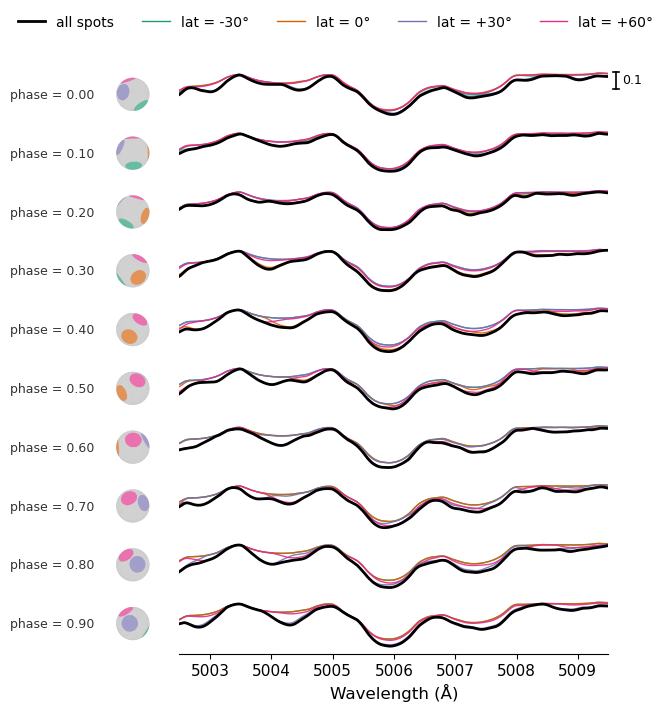

In [10]:
def _los_view_angles(mesh):
    # matplotlib (elev, azim) putting the camera on the observer's side, i.e. along -los_vector
    los = np.asarray(mesh.los_vector, float); los /= (np.linalg.norm(los) + 1e-12)
    obs = -los
    return float(np.degrees(np.arcsin(np.clip(obs[2], -1, 1)))), float(np.degrees(np.arctan2(obs[1], obs[0])))


# face colours for the insets: dominant spot, grey outside the outer radii
_best = np.argmax(W_SPOTS, axis=1)
_face_colors = np.array([mpl.colors.to_rgba(c) for c in SPOT_COLORS])[_best]
_face_colors[W_SPOTS.max(axis=1) <= 0] = mpl.colors.to_rgba('0.75')

N_ROWS = 10
row_idx = np.linspace(0, N_PHASES, N_ROWS, endpoint=False).astype(int)

fig, ax = plt.subplots(figsize=(6.5, 7))
ax.axis('off')
fig.subplots_adjust(left=0.26, right=0.92, top=0.90, bottom=0.06)

combined_lw, spot_lw = 2.0, 1.0
curves = [all_norm[k] for k in row_idx] + [seq[k] for seq in single_norm for k in row_idx]
g_min, g_max = min(c.min() for c in curves), max(c.max() for c in curves)
g_range = g_max - g_min + 1e-12
n = N_ROWS
row_height = 1.0 / n
prof_scale = 0.75 * row_height
y0 = 1.0 - row_height / 2


def to_row(flux, baseline):
    return baseline + (flux - g_min) * (prof_scale / g_range) - prof_scale / 2


for r, k in enumerate(row_idx):
    baseline = y0 - r * row_height
    for seq, col in zip(single_norm, SPOT_COLORS):
        ax.plot(vws, to_row(seq[k], baseline), color=col, alpha=0.9, linewidth=spot_lw)
    ax.plot(vws, to_row(all_norm[k], baseline), color='black', linewidth=combined_lw)

ax.set_xlim(WL_MIN, WL_MAX)
ax.set_ylim(0, 1)

# flux scale: a bar of 0.1 in normalised flux next to the top row (the rows share one scale)
bar = 0.1 * prof_scale / g_range
# drawn just outside the right edge of the top row so it overlaps nothing
x_bar = WL_MAX + 0.12
y_top = to_row(np.array([1.0]), y0)[0]
ax.plot([x_bar, x_bar], [y_top - bar, y_top], color='black', lw=1.2, clip_on=False)
ax.plot([x_bar - 0.05, x_bar + 0.05], [y_top, y_top], color='black', lw=1.2, clip_on=False)
ax.plot([x_bar - 0.05, x_bar + 0.05], [y_top - bar, y_top - bar], color='black', lw=1.2, clip_on=False)
ax.text(x_bar + 0.1, y_top - bar / 2, '0.1', ha='left', va='center', fontsize=9, clip_on=False)

legend_handles = [Line2D([0], [0], color='black', linewidth=combined_lw, label='all spots')] + \
                 [Line2D([0], [0], color=c, linewidth=spot_lw, label=l) for c, l in zip(SPOT_COLORS, SPOT_LABELS)]
ax.legend(handles=legend_handles, loc='upper center', bbox_to_anchor=(0.5, 0.99),
          bbox_transform=fig.transFigure, ncol=5, frameon=False)

ax_x = ax.twiny()
ax_x.set_xlim(WL_MIN, WL_MAX)
ax_x.xaxis.set_ticks_position('bottom'); ax_x.xaxis.set_label_position('bottom')
for side in ('top', 'left', 'right'):
    ax_x.spines[side].set_visible(False)
ax_x.set_yticks([])
ax_x.set_xticks(np.arange(5003, 5010, 1))
ax_x.set_xlabel('Wavelength (Å)')

# insets: the hemisphere facing the observer at each phase, spots in the colours of their profiles
ax_pos = ax.get_position()
inset_h = 0.95 * row_height * ax_pos.height
inset_w = inset_h * fig.get_figheight() / fig.get_figwidth()
inset_right = ax_pos.x0 - 0.03
inset_left = max(0.005, inset_right - inset_w)
for r, k in enumerate(row_idx):
    mesh = mts_all[k]
    baseline = y0 - r * row_height
    fig_y = ax_pos.y0 + baseline * ax_pos.height
    fig.text(inset_left - 0.015, fig_y, f"phase = {phases[k]:.2f}", ha='right', va='center', fontsize=9, color='0.2')
    ia = fig.add_axes([inset_left, fig_y - inset_h / 2, inset_w, inset_h], projection='3d')
    ia.set_axis_off(); ia.set_proj_type('ortho'); ia.patch.set_alpha(0.0)
    fc = _face_colors.copy()
    fc[np.asarray(mesh.mus) <= 0] = (0.0, 0.0, 0.0, 0.0)
    ia.add_collection(art3d.Poly3DCollection(mesh.mesh_elements, facecolors=fc, edgecolor='none', linewidths=0))
    _set_axes_centered(ia, _mesh_center(mesh), 1.0 * float(mesh.radius))
    ia.set_box_aspect((1, 1, 1))
    ia.view_init(*_los_view_angles(mesh))

fig.savefig('kochukov2017_spectra_comparison_nlte.pdf', bbox_inches='tight', dpi=300)   # name used by the tex
fig.savefig('kochukhov2017_fe_lte_profiles.pdf', bbox_inches='tight', dpi=300)
plt.show()


## Figure: spotted vs unspotted profiles on a true flux axis, and their difference (paper Fig. 9)

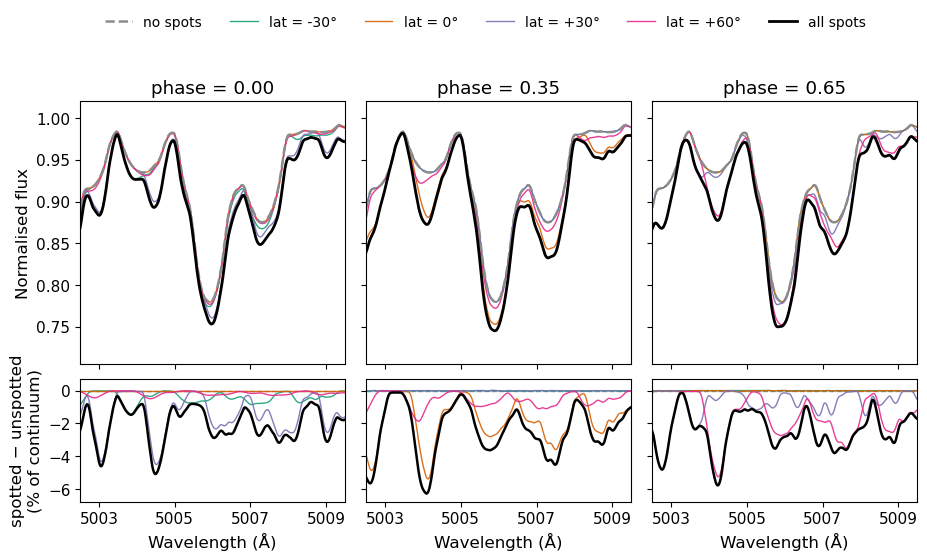

In [11]:
sel = [0, N_PHASES * 7 // 20, N_PHASES * 13 // 20]
fig, axes = plt.subplots(2, len(sel), figsize=(3.6 * len(sel), 5.2), sharex=True,
                         gridspec_kw={'height_ratios': [3, 1.4], 'hspace': 0.08, 'wspace': 0.08})
for j, k in enumerate(sel):
    ax, axd = axes[0, j], axes[1, j]
    ax.plot(vws, nospot_norm, color='0.55', ls='--', lw=1.8, label='no spots', zorder=2)
    for seq, c, l in zip(single_norm, SPOT_COLORS, SPOT_LABELS):
        ax.plot(vws, seq[k], color=c, lw=1.0, alpha=0.9, label=l, zorder=1)
    ax.plot(vws, all_norm[k], color='black', lw=2.0, label='all spots', zorder=3)
    ax.set_title(f'phase = {phases[k]:.2f}')
    axd.axhline(0, color='0.55', ls='--', lw=1.0)
    for seq, c in zip(single_norm, SPOT_COLORS):
        axd.plot(vws, 100 * (seq[k] - nospot_norm), color=c, lw=1.0, alpha=0.9)
    axd.plot(vws, 100 * (all_norm[k] - nospot_norm), color='black', lw=1.8)
    axd.set_xlabel('Wavelength (Å)')
    axd.set_xlim(WL_MIN, WL_MAX)
    axd.set_xticks(np.arange(5003, 5010, 2))
    if j > 0:
        ax.tick_params(labelleft=False); axd.tick_params(labelleft=False)
axes[0, 0].set_ylabel('Normalised flux')
axes[1, 0].set_ylabel('spotted − unspotted\n(% of continuum)')
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', bbox_to_anchor=(0.5, 0.995), ncol=6, frameon=False, fontsize=10)
ymin = min(a.min() for a in all_norm + [nospot_norm])
for ax in axes[0]:
    ax.set_ylim(ymin - 0.03, 1.02)
dmin = min(100 * (all_norm[k] - nospot_norm).min() for k in sel)
for ax in axes[1]:
    ax.set_ylim(dmin - 0.5, 0.7)
fig.savefig('kochukov2017_photosphere_vs_spots.pdf', bbox_inches='tight', dpi=300)
fig.savefig('kochukhov2017_fe_lte_photosphere_vs_spots.pdf', bbox_inches='tight', dpi=300)
plt.show()


## Numbers quoted in the paper / referee response

In [12]:
print(f'Teff = {TEFF:.0f} K, log g = {LOGG}, xi = {VMICRO} km/s, R = {RADIUS} Rsun')
print(f'i = {INCL:.0f} deg, v sin i = {VSINI:.0f} km/s -> v_eq = {V_EQ:.2f} km/s, P_rot = {PERIOD_H:.2f} h')
print(f'A(Fe): photosphere {A_FE_BG:.3f} ([Fe/H] {A_FE_BG - A_FE_SUN:+.2f}), spots {A_FE_SPOT:.3f} ([Fe/H] {A_FE_SPOT - A_FE_SUN:+.2f})')
print(f'{len(vws)} wavelengths {WL_MIN}-{WL_MAX} A at {WL_STEP} A; {N_PHASES} phases; {mt.mesh_elements.shape[0]} elements')
print(f'photospheric blend depth: {depth_raw:.3f} (native), {depth_conv:.3f} (R = {R_INST:.0f})')
print(f'spot signature max over phases: {100 * sig.max():.1f}% of the continuum')
for lat, seq in zip(SPOT_LATS, single_norm):
    amp = max(np.abs(s - nospot_norm).max() for s in seq)
    print(f'  single spot lat {lat:+5.1f}: max |difference| {100 * amp:.1f}%')


Teff = 8000 K, log g = 4.0, xi = 2.0 km/s, R = 1.0 Rsun
i = 60 deg, v sin i = 40 km/s -> v_eq = 46.19 km/s, P_rot = 26.29 h
A(Fe): photosphere 8.035 ([Fe/H] +0.58), spots 9.535 ([Fe/H] +2.08)
701 wavelengths 5002.5-5009.5 A at 0.01 A; 20 phases; 20480 elements
photospheric blend depth: 0.220 (native), 0.220 (R = 110000)
spot signature max over phases: 7.6% of the continuum
  single spot lat -30.0: max |difference| 2.3%
  single spot lat  +0.0: max |difference| 5.4%
  single spot lat +30.0: max |difference| 6.7%
  single spot lat +60.0: max |difference| 5.4%
